# P1.01 — House prices, rents and mortgage rates

**Questions:** RQ1.1 (price trends), RQ1.3 (real prices and rents), RQ1.7 (mortgage rates), RQ4.1 (largest
increases by municipality).

Data: `panel_municipality_year` and `national_quarterly` (see `docs/methodology.md`). All values are
deflated to constant 2024 euros with the INE consumer price index unless marked nominal.

In [1]:
from pthousing.analysis import descriptive as desc
from pthousing.data import build_panel
from pthousing.viz import charts, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
nat = build_panel.read("national_quarterly")
print(f"panel: {panel.shape}, national: {nat.shape}")

panel: (9548, 54), national: (86, 25)


## National house price index: nominal vs real

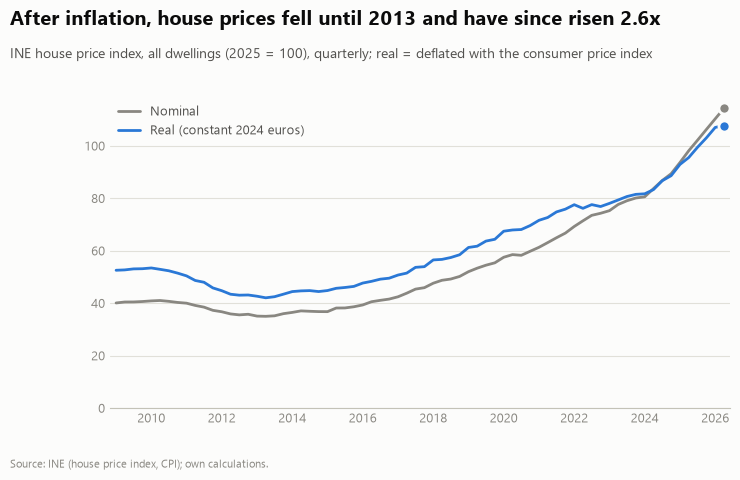

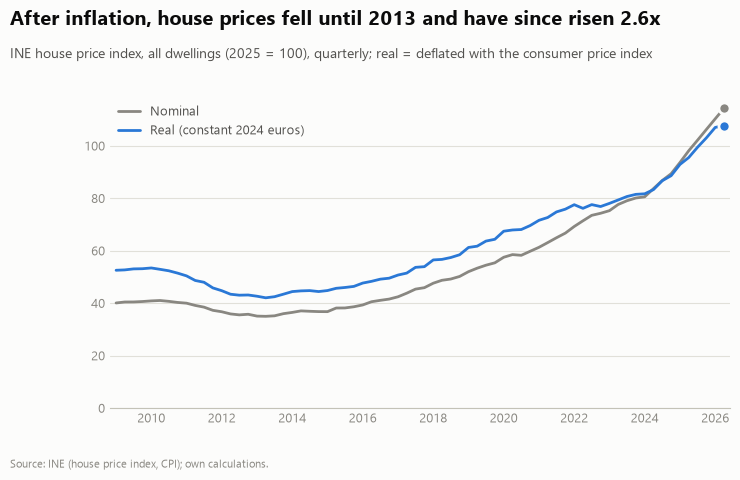

In [2]:
fig = charts.hpi_real_vs_nominal(nat)
style.save_fig(fig, "p1", "hpi_real_vs_nominal")
fig

## Portugal against the EU
Portugal's index sits far above the EU27 and the five peers; Ireland and Spain, the next highest, are at about 2.0.

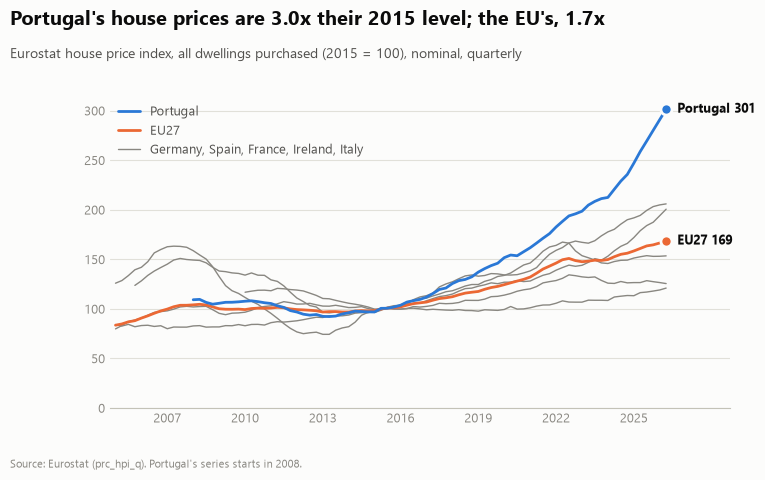

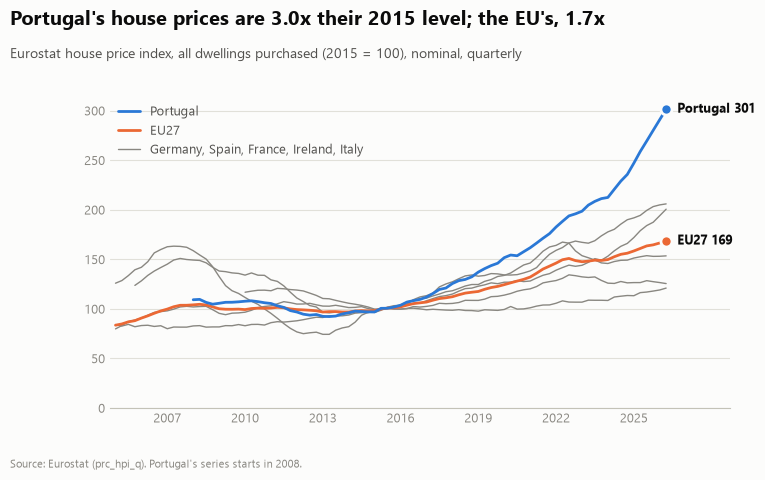

In [3]:
fig = charts.hpi_peers(nat)
style.save_fig(fig, "p1", "hpi_peers")
fig

## Prices per m² across municipalities, 2016–2025
Municipal prices are published from 2016 (INE, AT data). The band shows the spread between municipalities.

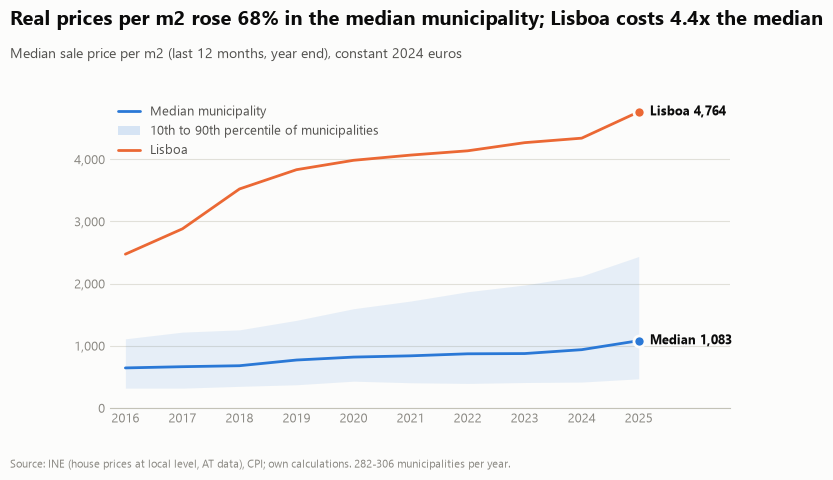

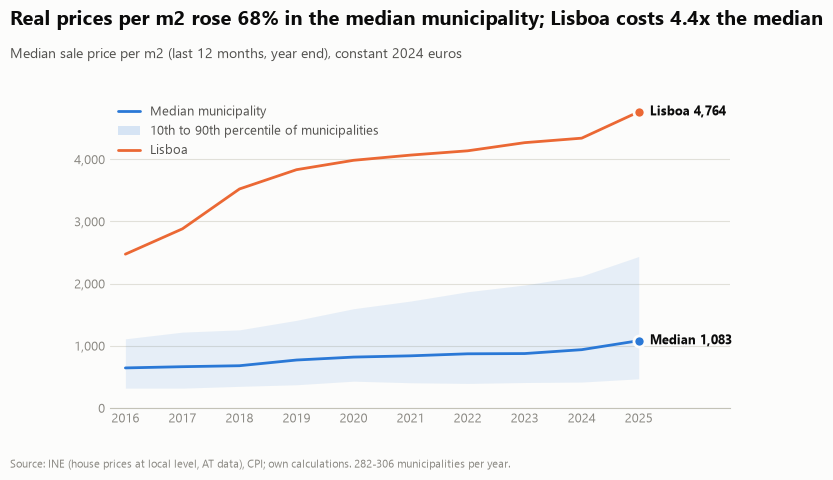

In [4]:
prices = panel[panel["year"].between(2016, 2025)]
fan = desc.yearly_quantiles(prices, "price_sqm_eur_real")
lisboa = prices[prices["muni_name"] == "Lisboa"].set_index("year")["price_sqm_eur_real"]
fig = charts.price_fan(fan, lisboa, "Lisboa", (int(fan["n"].min()), int(fan["n"].max())))
style.save_fig(fig, "p1", "price_sqm_real_fan")
fig

## Real rents and prices since 2020
Rents are published from 2020, and only for municipalities with at least 33 new leases a year, so the
comparison uses a fixed set of municipalities that have both series in every year.

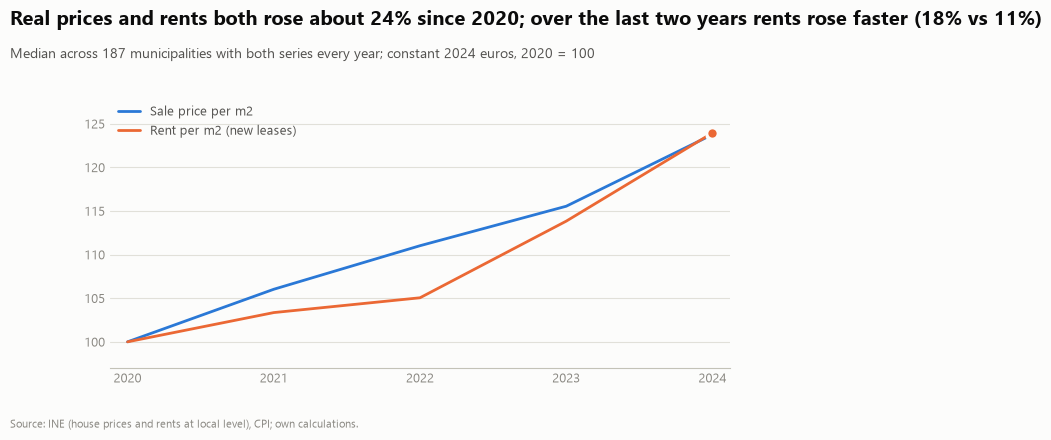

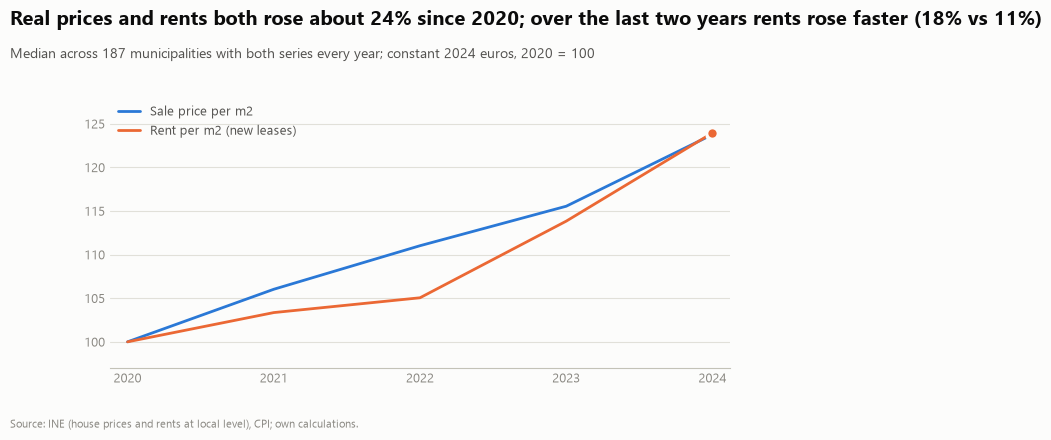

In [5]:
years = list(range(2020, 2025))
cols = ["price_sqm_eur_real", "rent_sqm_eur_real"]
fixed = desc.balanced_sample(panel, cols, years)
index = desc.median_index(fixed, cols, 2020).rename(columns={cols[0]: "price", cols[1]: "rent"})
n_fixed = fixed["muni_code"].nunique()
fig = charts.real_growth_index(index, n_fixed, 2020)
style.save_fig(fig, "p1", "real_price_rent_index")
fig

## Mortgage rates and payments

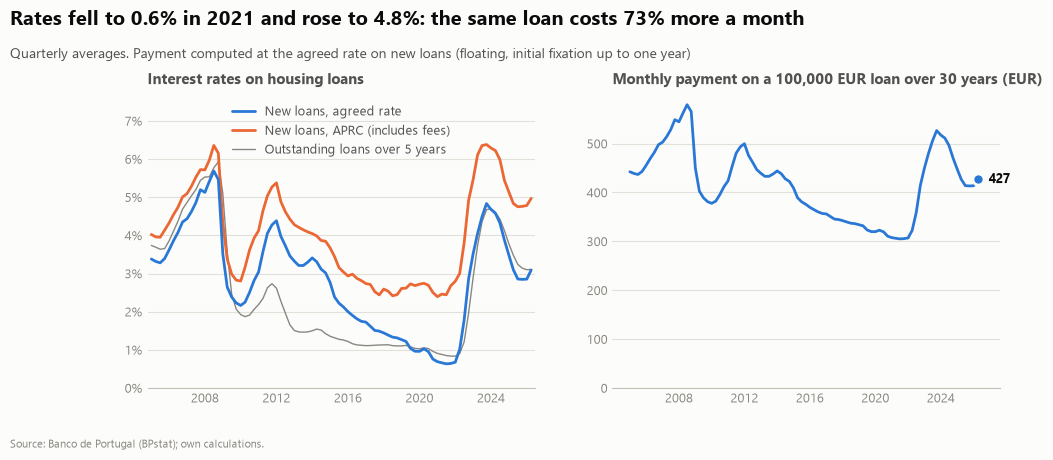

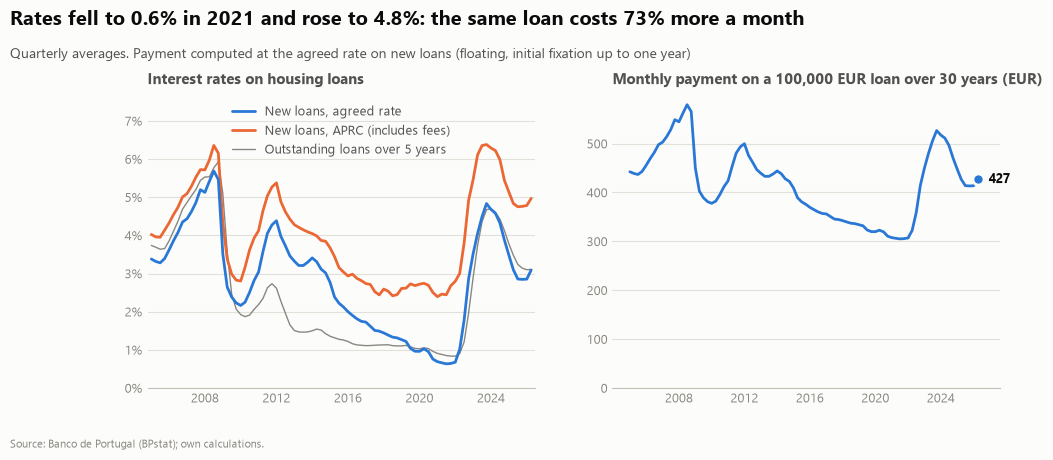

In [6]:
fig = charts.mortgage_rates(nat)
style.save_fig(fig, "p1", "mortgage_rates")
fig

## Where did prices and rents rise most? (RQ4.1)
Real growth per municipality; the full tables are saved next to the figures.

In [7]:
names = panel.drop_duplicates("muni_code").set_index("muni_code")[["muni_name", "district"]]
growth = names.join(
    [
        desc.change(panel, "price_sqm_eur_real", 2016, 2025, "pct").rename(
            "price_real_growth_pct_2016_2025"
        ),
        desc.change(panel, "rent_sqm_eur_real", 2020, 2024, "pct").rename(
            "rent_real_growth_pct_2020_2024"
        ),
        panel[panel["year"] == 2025]
        .set_index("muni_code")["price_sqm_eur_real"]
        .rename("price_sqm_eur_real_2025"),
    ]
).round(1)
growth = growth.reset_index()
style.save_table(
    growth.sort_values("price_real_growth_pct_2016_2025", ascending=False),
    "p1",
    "real_growth_by_municipality",
)
top_prices = growth.dropna(subset=["price_real_growth_pct_2016_2025"]).nlargest(
    10, "price_real_growth_pct_2016_2025"
)
top_rents = growth.dropna(subset=["rent_real_growth_pct_2020_2024"]).nlargest(
    10, "rent_real_growth_pct_2020_2024"
)
display_cols = [
    "muni_name",
    "district",
    "price_real_growth_pct_2016_2025",
    "price_sqm_eur_real_2025",
]
top_prices[display_cols]

,muni_name,district,price_real_growth_pct_2016_2025,price_sqm_eur_real_2025
301,Lajes do Pico,Ilha do Pico,547.0,1054.4
95,Portel,Évora,292.8,767.1
303,São Roque do Pico,Ilha do Pico,275.0,1532.2
119,Celorico da Beira,Guarda,250.3,482.7
241,Boticas,Vila Real,243.1,616.6
220,Barreiro,Setúbal,232.6,2450.7
222,Moita,Setúbal,207.2,2175.2
289,Vila do Porto,Ilha de Santa Maria,183.4,1351.4
167,Castelo de Vide,Portalegre,183.2,688.9
157,Sintra,Lisboa,181.8,2670.6


In [8]:
top_rents[["muni_name", "district", "rent_real_growth_pct_2020_2024"]]

,muni_name,district,rent_real_growth_pct_2020_2024
278,Calheta,Ilha da Madeira,92.4
229,Sines,Setúbal,82.4
233,Monção,Viana do Castelo,67.4
225,Santiago do Cacém,Setúbal,60.1
134,Batalha,Leiria,59.1
141,Nazaré,Leiria,58.9
221,Grândola,Setúbal,57.1
205,Entroncamento,Santarém,49.6
78,Miranda do Corvo,Coimbra,49.2
17,Vagos,Aveiro,47.1


By district: median real price and rent per m² across the municipalities of each district
(only municipalities with a value in both years, so the two medians describe the same set).

In [9]:
price_districts = desc.district_summary(panel, "price_sqm_eur_real", 2016, 2025)
price_districts["change_pct"] = 100 * (
    price_districts["median_2025"] / price_districts["median_2016"] - 1
)
rent_districts = desc.district_summary(panel, "rent_sqm_eur_real", 2020, 2024)
rent_districts["change_pct"] = 100 * (
    rent_districts["median_2024"] / rent_districts["median_2020"] - 1
)
style.save_table(price_districts.round(2), "p1", "price_sqm_real_by_district_2016_2025")
style.save_table(rent_districts.round(2), "p1", "rent_sqm_real_by_district_2020_2024")
price_districts.sort_values("change_pct", ascending=False).round(1)

,district,median_2016,median_2025,municipalities_n,change,change_pct
9,Ilha de Santa Maria,476.9,1351.4,1,874.6,183.4
15,Ilha do Pico,397.8,1054.4,3,656.6,165.1
2,Setúbal,925.0,2411.7,13,1486.7,160.7
1,Lisboa,1008.9,2608.1,16,1599.2,158.5
5,Porto,789.6,1682.2,18,892.6,113.0
6,Ilha de São Miguel,693.1,1429.1,6,736.0,106.2
0,Faro,1440.2,2901.2,16,1461.0,101.4
8,Leiria,687.2,1368.5,16,681.4,99.2
7,Braga,694.9,1375.4,14,680.4,97.9
3,Ilha de Porto Santo,1193.4,2354.0,1,1160.6,97.3


## Key numbers

In [10]:
real = nat.set_index("period_start")["hpi_total_real_b2025"].dropna()
print(
    f"Real HPI: low {real.min():.1f} in {real.idxmin().date()}, latest {real.iloc[-1]:.1f} ({real.iloc[-1] / real.min():.2f}x)"
)
print(
    f"Median real price/m2: {fan['q50'].iloc[0]:.0f} (2016) -> {fan['q50'].iloc[-1]:.0f} (2025), {100 * (fan['q50'].iloc[-1] / fan['q50'].iloc[0] - 1):.0f}%"
)
print(
    f"Fixed sample ({n_fixed} municipalities), 2020 -> 2024: real price {index['price'].iloc[-1] - 100:+.0f}%, real rent {index['rent'].iloc[-1] - 100:+.0f}%"
)
print(
    f"Municipalities with real price growth > 50% since 2016: {(growth['price_real_growth_pct_2016_2025'] > 50).sum()} of {growth['price_real_growth_pct_2016_2025'].notna().sum()}"
)

Real HPI: low 42.0 in 2013-04-01, latest 107.7 (2.56x)
Median real price/m2: 645 (2016) -> 1083 (2025), 68%
Fixed sample (187 municipalities), 2020 -> 2024: real price +24%, real rent +24%
Municipalities with real price growth > 50% since 2016: 213 of 302
